Choose a starting pension index. A value of 100 means the pension starts at its assumed benchmark value relative to earnings. 100
Enter a simulation horizon in years: 30


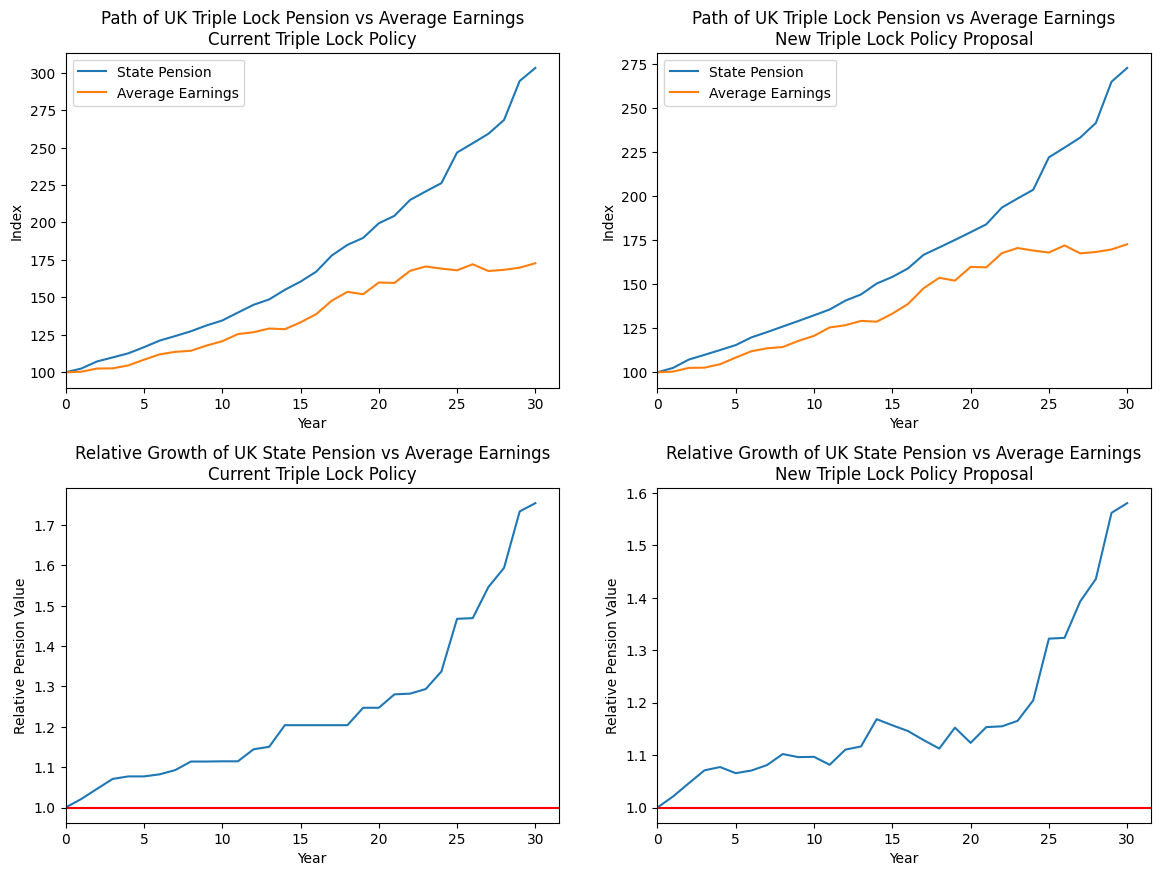

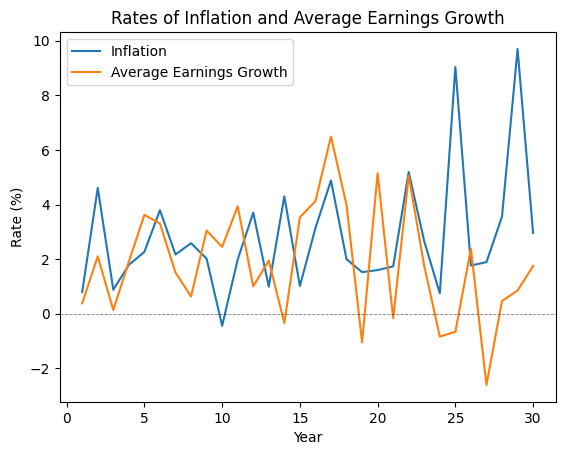

There were inflation shocks in years: [25, 29]


In [1]:
import matplotlib.pyplot as plt
import numpy as np

rng = np.random.default_rng()

starting_pension_index = float(input("Choose a starting pension index. A value of 100 means the pension starts at its assumed benchmark value relative to earnings. "))
while starting_pension_index < 100:
  starting_pension_index = float(input("Choose a new starting pension index. The number must be 100 or above: "))

old_pension_index = new_pension_index = starting_pension_index
average_earnings_index = 100

pension_rise_floor = 0.025

simulation_horizon_in_years = int(input("Enter a simulation horizon in years: "))
while simulation_horizon_in_years < 1:
  simulation_horizon_in_years = int(input(" The simulation horizon must be at least one year. Enter a new value: "))
years = list(range(0, simulation_horizon_in_years + 1))

old_pension_history = [old_pension_index]
new_pension_history = [new_pension_index]
average_earnings_history = [average_earnings_index]
old_pension_relative_value_history = [old_pension_index / average_earnings_index]
new_pension_relative_value_history = [new_pension_index / average_earnings_index]
inflation_history = []
average_earnings_growth_history = []

inflation_shock_probability = 0.05
inflation_shock_mean = 0.06
inflation_shock_sd = 0.02
inflation_shock_years = []

for year in range(1, simulation_horizon_in_years + 1):
  inflation = rng.normal(0.02, 0.015)
  if rng.random() < inflation_shock_probability:
    inflation_shock = rng.normal(inflation_shock_mean, inflation_shock_sd)
    inflation += inflation_shock
    inflation_shock_years.append(year)
  average_earnings_growth = rng.normal(0.03, 0.02)
  if inflation <= -1:
    raise ValueError("Invalid economic scenario")
  if average_earnings_growth <= -1:
    raise ValueError("Invalid economic scenario")
  average_earnings_index = average_earnings_index * (1 + average_earnings_growth)
  old_pension_index = old_pension_index * (1 + max(inflation, average_earnings_growth, pension_rise_floor))
  new_pension_index = max((new_pension_index * (1 + max(inflation, pension_rise_floor))), average_earnings_index)
  old_pension_relative_value = old_pension_index / average_earnings_index
  new_pension_relative_value = new_pension_index / average_earnings_index
  old_pension_history.append(old_pension_index)
  new_pension_history.append(new_pension_index)
  average_earnings_history.append(average_earnings_index)
  new_pension_relative_value_history.append(new_pension_relative_value)
  old_pension_relative_value_history.append(old_pension_relative_value)
  inflation_history.append(inflation)
  average_earnings_growth_history.append(average_earnings_growth)


plt.figure(figsize=(14, 10))

plt.subplot(2,2,1) #Graph for Old Pension vs Earnings
plt.plot(years, old_pension_history, label='State Pension')
plt.plot(years, average_earnings_history, label='Average Earnings')
plt.xlim(left=0)
plt.xlabel('Year')
plt.ylabel('Index')
plt.title('Path of UK Triple Lock Pension vs Average Earnings\nCurrent Triple Lock Policy')
plt.legend()


plt.subplot(2,2,2) #Graph for New Pension vs Earnings
plt.plot(years, new_pension_history, label='State Pension')
plt.plot(years, average_earnings_history, label='Average Earnings')
plt.xlim(left=0)
plt.xlabel('Year')
plt.ylabel('Index')
plt.title('Path of UK Triple Lock Pension vs Average Earnings\nNew Triple Lock Policy Proposal')
plt.legend()

plt.subplot(2,2,3) #Graph for Relative Value of Old Pension
plt.plot(years, old_pension_relative_value_history)
plt.xlim(left=0)
plt.axhline(y=1, color='red')
plt.xlabel('Year')
plt.ylabel('Relative Pension Value')
plt.title('Relative Growth of UK State Pension vs Average Earnings\nCurrent Triple Lock Policy')

plt.subplot(2,2,4) #Graph for Relative Value of New Pension
plt.plot(years, new_pension_relative_value_history)
plt.xlim(left=0)
plt.axhline(y=1, color='red')
plt.xlabel('Year')
plt.ylabel('Relative Pension Value')
plt.title('Relative Growth of UK State Pension vs Average Earnings\nNew Triple Lock Policy Proposal')

plt.subplots_adjust(hspace=0.3)
plt.show()

plt.plot(years[1:], [x*100 for x in inflation_history], label='Inflation')
plt.plot(years[1:], [x*100 for x in average_earnings_growth_history], label='Average Earnings Growth')
plt.axhline(y=0, color='black', linestyle='--', linewidth=0.6, alpha=0.5)
plt.xlabel('Year')
plt.ylabel('Rate (%)')
plt.title('Rates of Inflation and Average Earnings Growth')
plt.legend()
plt.show()

if inflation_shock_years == []:
  print("There were no inflation shocks during the simulation period.")
else:
  print("There were inflation shocks in years:", inflation_shock_years)